In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

In [73]:
recordings = pd.read_csv("cleaned/cardiac_recordings_cleaned.csv")
samples = pd.read_csv("cleaned/cardiac_signal_samples_cleaned.csv")

# Résumé des fichiers `cardiac`

Le fichier `cardiac_recordings` contient des informations sur les diagnostics des patients, ainsi que leur interprétation.

Le fichier `cardiac_signal_samples` contient le résultat du diagnostic : le signal cardiac sur deux canaux en fonction du temps.

# Corrélation des variables numériques

## Sur `cardiac _recordings` :

On retire `channel_count` parce que cette variable est toujours à 2 donc on peut rien en tirer d'utile. On garde `sampling_interval_ms` pour vérifier qu'elle est redondante avec `sampling_rate_hz`.

Text(0.5, 1.0, 'Corrélations (Pearson) : cardiac_recordings')

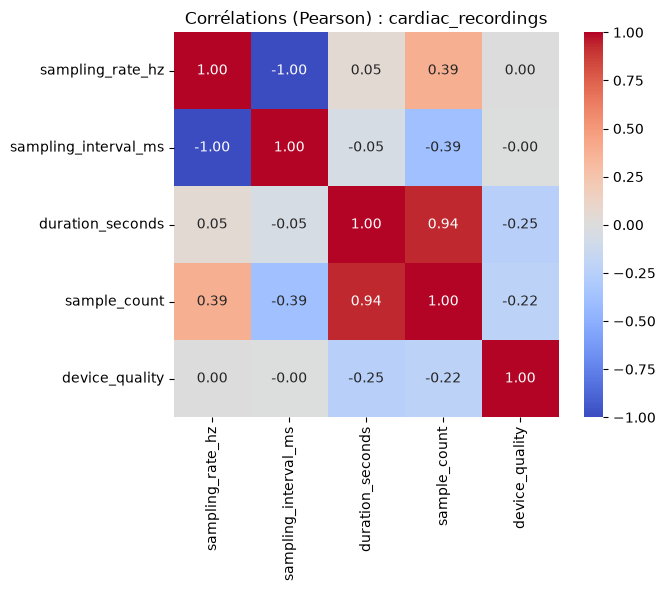

In [74]:
corr = recordings[["sampling_rate_hz", "sampling_interval_ms", "duration_seconds", "sample_count", "device_quality"]].corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations (Pearson) : cardiac_recordings")

## Sur `cardiac_signal_samples`



Text(0.5, 1.0, 'Corrélations (Pearson) : cardiac_signals_samples')

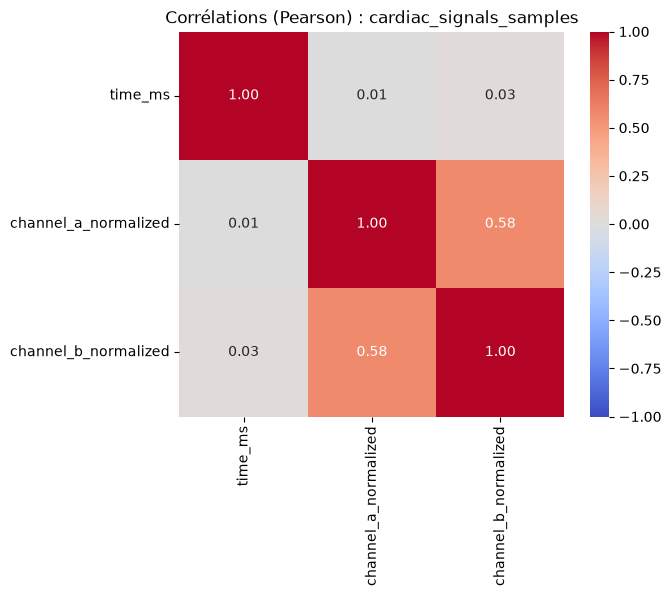

In [75]:
corr = samples[
    ["time_ms", "channel_a_normalized", "channel_b_normalized"]].corr()
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations (Pearson) : cardiac_signals_samples")
## Sur `cardiac_signal_samples`

Il est assez logique que les deux canaux soit plutôt fortement corrélés entre eux. Il est serait intéressant de visualiser à quoi ressemble un signal ressemble le premier patient de `cardiac_recordings` :

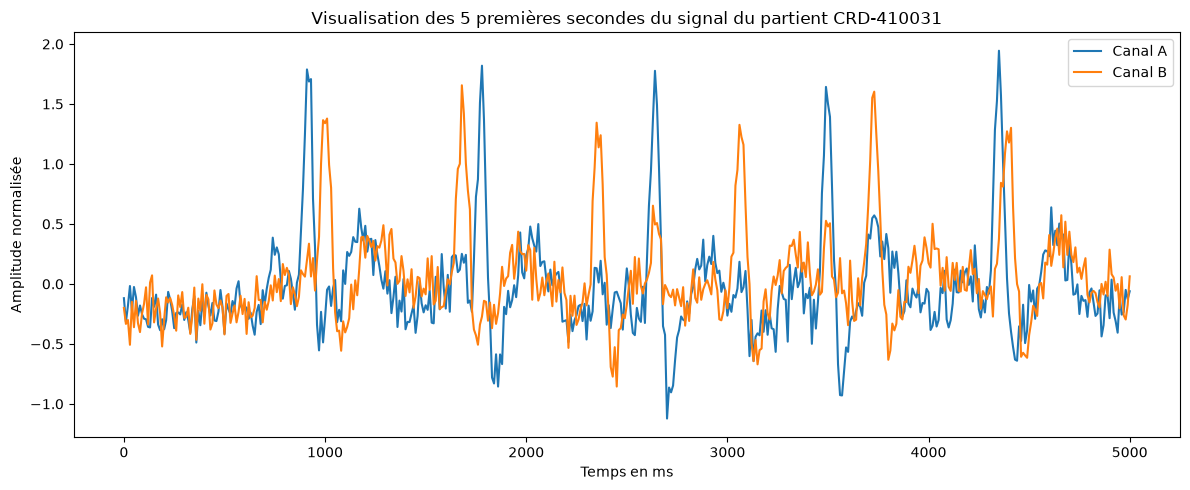

In [91]:
sample_recording_id = samples["recording_id"].iloc[38]
subset = samples[
(samples["recording_id"] == sample_recording_id)
    & (samples["time_ms"] <= 5000)]

plt.figure(figsize=(12, 5))
sns.lineplot(data=subset, x="time_ms", y="channel_a_normalized", label="Canal A")
sns.lineplot(data=subset, x="time_ms", y="channel_b_normalized", label="Canal B")

plt.title(f"Visualisation des 5 premières secondes du signal du partient {sample_recording_id}")
plt.xlabel("Temps en ms")
plt.ylabel("Amplitude normalisée")
plt.legend()
plt.tight_layout()
plt.show()

On voit en effet que les signaux ne sont pas tout à fait pareils : il y a des différences dans l'amplitude et dans le timing des pics (très probablement causés par du bruit et la différence entre les capteurs).

# Clustering sur `cardiac_recordings`

### Choix des variables

On écarte les identifiants (recording_id, patient_number, etc...), les colonnes constantes (amplitude_unit, archive_status, channel_count) et la redondance (sampling_interval_ms). On conserve les variables numériques pertinentes et on encode les variables catégorielles importantes.

In [77]:
num_cols = [
    "sampling_rate_hz",
    "duration_seconds",
    "sample_count",
    "device_quality",
]
cat_cols = [
    "recording_context",
    "device_model",
    "automated_interpretation",
    "recording_notes_code",
]

# on extrait et encode one-hot les variables catégorielles
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(recordings[num_cols])

X_cat = pd.get_dummies(recordings[cat_cols], drop_first=True)
X_combined = np.hstack([X_num_scaled, X_cat.values.astype(float)])


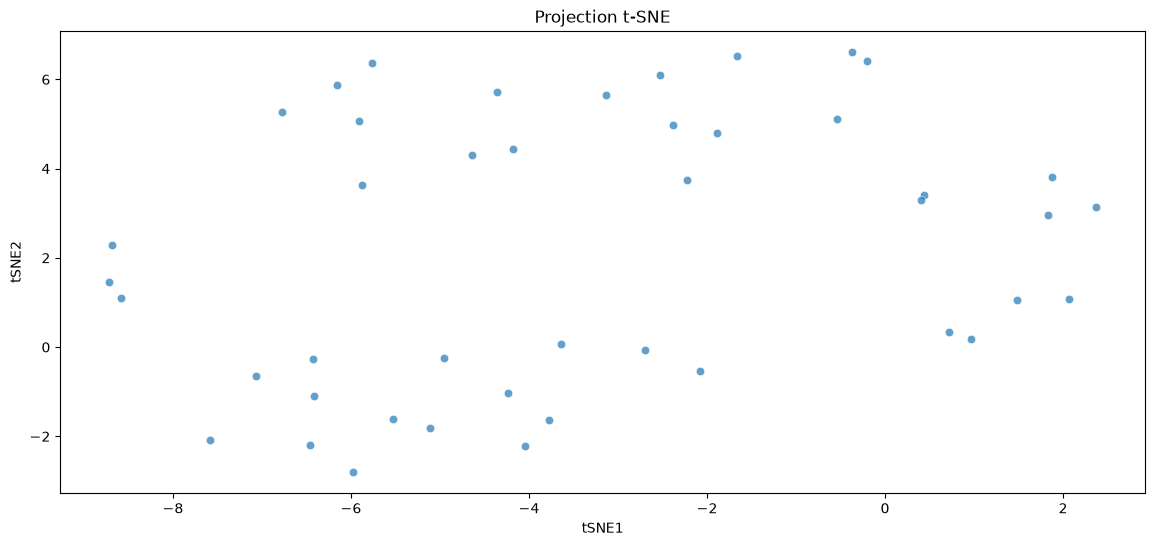

In [78]:
# Projection PCA (Linéaire) et t-SNE (Non-linéaire)
fig, axe = plt.subplots(figsize=(14, 6))

tsne = TSNE(n_components=2, perplexity=15, random_state=2903)
tsne_res = tsne.fit_transform(X_combined)
recordings["tSNE1"] = tsne_res[:, 0]
recordings["tSNE2"] = tsne_res[:, 1]
sns.scatterplot(x="tSNE1", y="tSNE2", data=recordings, ax=axe, alpha=0.7)
axe.set_title("Projection t-SNE")

plt.show()

On observe 4 clusters. Vérifions avec  K-Means. On vérifie `k_optimal` avec 2 méthodes.

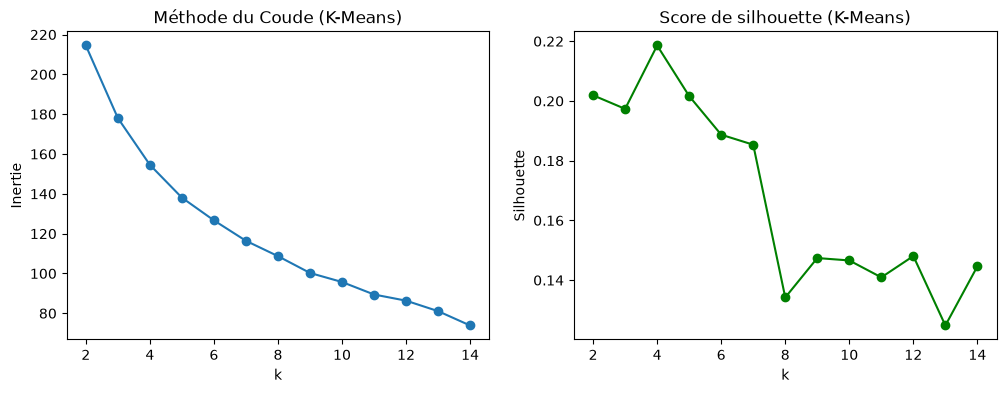

In [79]:
inertias = []
silhouettes = []
K_range = range(2, 15)

for k in K_range:
  km = KMeans(n_clusters=k, random_state=2903, n_init=10)
  labels = km.fit_predict(X_combined)
  inertias.append(km.inertia_)
  silhouettes.append(silhouette_score(X_combined, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker="o")
axes[0].set_title("Méthode du Coude (K-Means)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertie")

axes[1].plot(K_range, silhouettes, marker="o", color="green")
axes[1].set_title("Score de silhouette (K-Means)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.show()

Le k optimal semble être 4.

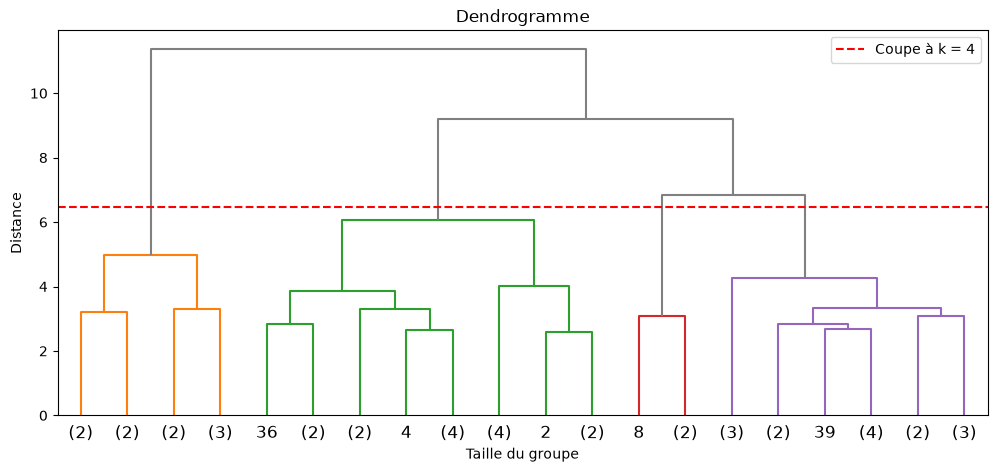

In [80]:
k_optimal = 4
Z = linkage(X_combined, method="ward")
seuil = (Z[-k_optimal, 2] + Z[-(k_optimal - 1), 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True,
    color_threshold=seuil,
    above_threshold_color="grey",
)
plt.axhline(y=seuil, color="r", linestyle="--", label=f"Coupe à k = {k_optimal}")
plt.title("Dendrogramme")
plt.xlabel("Taille du groupe")
plt.ylabel("Distance")
plt.legend()
plt.show()

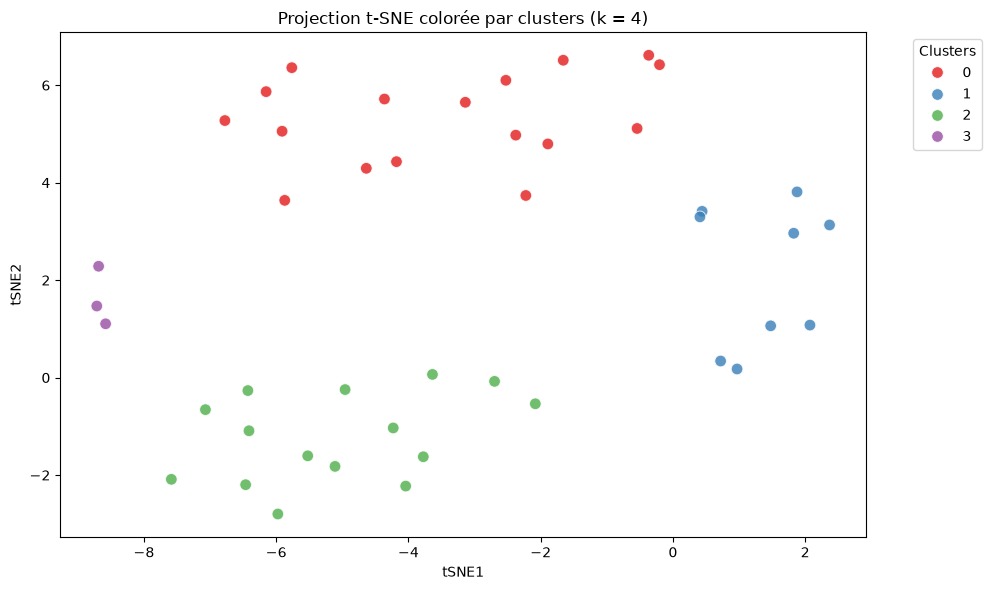

In [81]:
clustering = AgglomerativeClustering(n_clusters=k_optimal, metric="euclidean", linkage="ward")
recordings["cluster"] = clustering.fit_predict(X_combined)

fig, axe = plt.subplots(figsize=(10, 6))

tsne = TSNE(n_components=2, perplexity=15, random_state=2903)
tsne_res = tsne.fit_transform(X_combined)
recordings["tSNE1"] = tsne_res[:, 0]
recordings["tSNE2"] = tsne_res[:, 1]

sns.scatterplot(x="tSNE1", y="tSNE2", hue="cluster", data=recordings, palette="Set1", ax=axe, alpha=0.8, s=70)

axe.set_title(f"Projection t-SNE colorée par clusters (k = {k_optimal})")
plt.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Regardons maintenant ce qui différencie les cluster.

In [82]:
recordings["cluster"] = AgglomerativeClustering(
n_clusters=k_optimal, metric="euclidean", linkage="ward").fit_predict(X_combined)

print("Moyennes des variables numériques par cluster :")
display(recordings.groupby("cluster")[num_cols].mean())

Moyennes des variables numériques par cluster :


,sampling_rate_hz,duration_seconds,sample_count,device_quality
cluster,,,,
0,125.000000,17.588235,2198.529412,92.711765
1,113.888889,28.666667,3250.000000,86.344444
2,100.000000,17.400000,1740.000000,94.893333
3,100.000000,14.000000,1400.000000,81.200000


Les quatre clusters se distinguent principalement par la fréquence d'échantillonnage, le volume des données (durée et nombre d'échantillons) et la qualité du matériel.

Le cluster 0 regroupe des enregistrements de durée moyenne (environ 17,6 secondes) capturés à une fréquence élevée de 125 Hz, ce qui génère un nombre de points élevé (~2200 échantillons) associé à une très bonne qualité d'appareil (92,7).

Le cluster 1 correspond aux enregistrements longs (les plus étendus de la base avec près de 28,7 secondes et 3250 échantillons), réalisés à une fréquence d'environ 114 Hz et une bonne qualité d'appareil.

Le cluster 2 a une fréquence de 100 text Hz et une durée comparable au cluster 0 (~17,4 secondes), mais il se démarque par la meilleure qualité globale du dispositif (94,9), ce qui signifie de meilleures conditions de mesure.

Enfin, le cluster 3 a les enregistrements les plus courts (14 secondes et 1400 échantillons à 100 Hz), caractérisés par la qualité d'appareil la plus faible (81,2). Ce groupe semble avoir les sessions potentiellement réalisées à la hâte ou avec du matériel sous-optimal, ce qui permet d'isoler un sous-ensemble d'enregistrements à surveiller ou à écarter selon les critères de robustesse de l'analyse.

# Clustering sur `cardiac_signal_samples`

Le fichier `cardiac_signal_samples` contient des séries temporelles brutes (donc beaucoup de lignes) associées à chaque recording_id. Pour lui appliquer le même type de clustering, il faut d'abord agréger les signaux par enregistrement afin d'extraire des caractéristiques statistiques (moyenne, écart-type, minimum, maximum) pour chaque canal.

In [83]:
# Extraction de statistiques
df_samples_agg = (samples.groupby("recording_id").agg(
        {
            "channel_a_normalized": ["mean", "std", "min", "max"],
            "channel_b_normalized": ["mean", "std", "min", "max"],
            "time_ms": ["max", "count"],
        }
    )
    .reset_index()
)

# Aplatissement des colonnes multi-index
df_samples_agg.columns = ["_".join(col).strip("_") for col in df_samples_agg.columns.to_flat_index()]
print(f"Dimensions après agrégation : {df_samples_agg.shape}")
df_samples_agg.head(2)

Dimensions après agrégation : (44, 11)


,recording_id,channel_a_normalized_mean,channel_a_normalized_std,channel_a_normalized_min,channel_a_normalized_max,channel_b_normalized_mean,channel_b_normalized_std,channel_b_normalized_min,channel_b_normalized_max,time_ms_max,time_ms_count
0,CRD-410001,0.087112,0.462965,-1.045386,2.136718,0.061576,0.438764,-0.980360,2.129936,17990,1800
1,CRD-410002,0.103981,0.647488,-1.367120,3.169961,0.027772,0.443646,-1.140012,1.840513,14990,1500


On peut maintenant répéter les étapes précédentes.

In [84]:
# on sélectionne des variables et on fait la standardisation
feature_cols = [col for col in df_samples_agg.columns if col != "recording_id"]

scaler = StandardScaler()
X_samples_scaled = scaler.fit_transform(df_samples_agg[feature_cols])

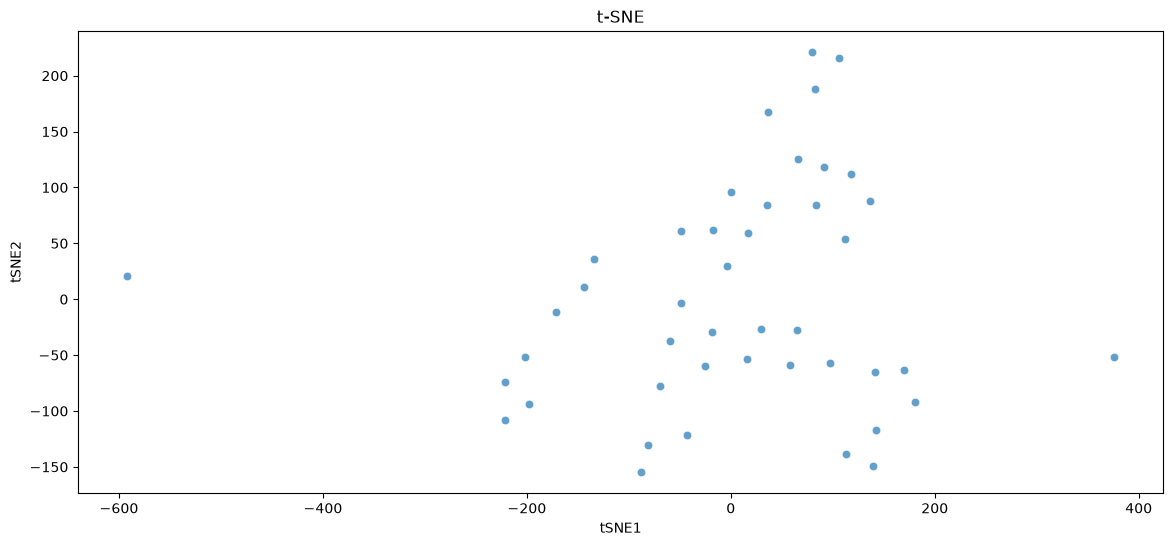

In [85]:
fig, axe = plt.subplots(figsize=(14, 6))

tsne = TSNE(n_components=2, perplexity=10, random_state=2903)
tsne_res = t_sne_res = tsne.fit_transform(X_samples_scaled)
df_samples_agg["tSNE1"] = tsne_res[:, 0]
df_samples_agg["tSNE2"] = tsne_res[:, 1]
sns.scatterplot(x="tSNE1", y="tSNE2", data=df_samples_agg, ax=axe, alpha=0.7)
axe.set_title("t-SNE")

plt.show()

On distingue ici deux anomalies, on essaiera d'expliquer d'où elles viennent plus tard.

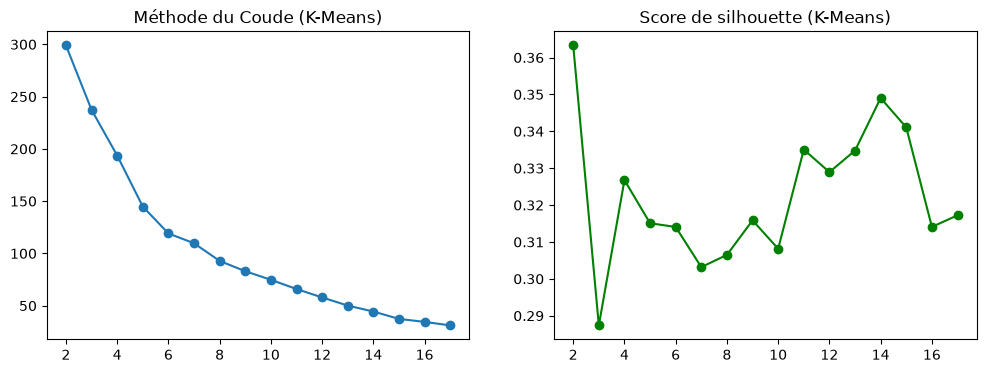

In [86]:
inertias = []
silhouettes = []
K_range = range(2, 18)

for k in K_range:
  km = KMeans(n_clusters=k, random_state=2903, n_init=10)
  labels = km.fit_predict(X_samples_scaled)
  inertias.append(km.inertia_)
  silhouettes.append(silhouette_score(X_samples_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker="o")
axes[0].set_title("Méthode du Coude (K-Means)")
axes[1].plot(K_range, silhouettes, marker="o", color="green")
axes[1].set_title("Score de silhouette (K-Means)")
plt.show()

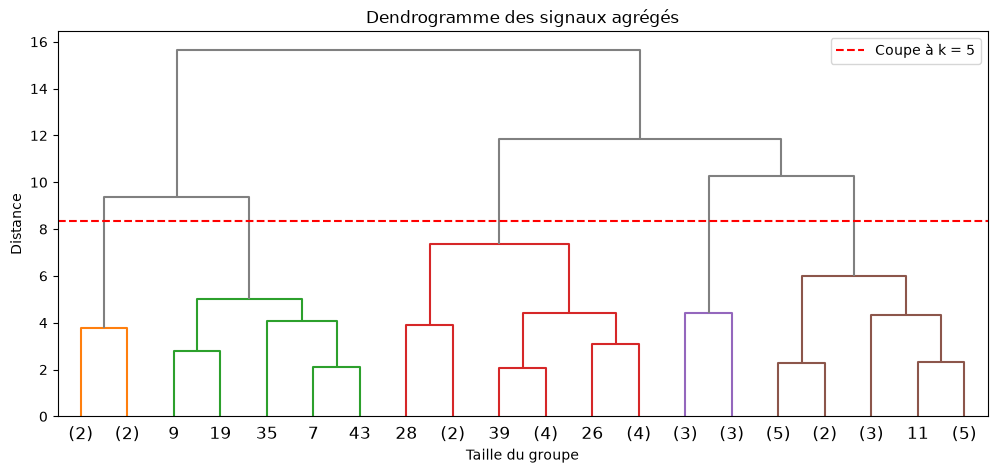

In [87]:
k_optimal = 5
Z = linkage(X_samples_scaled, method="ward")
seuil = (Z[-k_optimal, 2] + Z[-(k_optimal - 1), 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True,
    color_threshold=seuil,
    above_threshold_color="grey",
)
plt.axhline(y=seuil, color="r", linestyle="--", label=f"Coupe à k = {k_optimal}")
plt.title("Dendrogramme des signaux agrégés")
plt.xlabel("Taille du groupe")
plt.ylabel("Distance")
plt.legend()
plt.show()

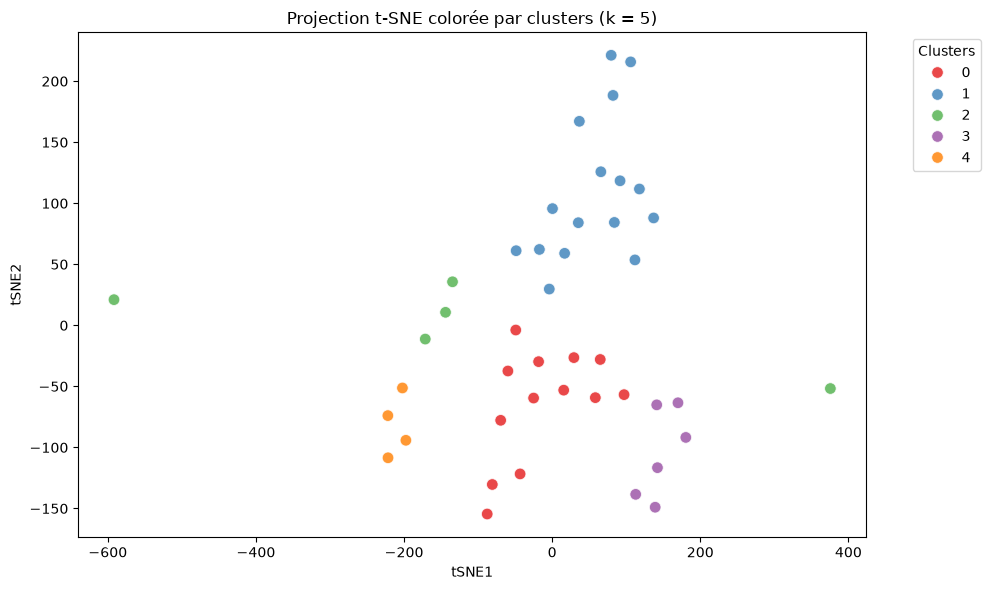

In [88]:
clustering = AgglomerativeClustering(n_clusters=k_optimal, metric="euclidean", linkage="ward")
df_samples_agg["cluster"] = clustering.fit_predict(X_samples_scaled)

fig, axe = plt.subplots(figsize=(10, 6))

tsne = TSNE(n_components=2, perplexity=10, random_state=2903)
tsne_res = tsne.fit_transform(X_samples_scaled)
df_samples_agg["tSNE1"] = tsne_res[:, 0]
df_samples_agg["tSNE2"] = tsne_res[:, 1]

sns.scatterplot( x="tSNE1", y="tSNE2", hue="cluster", data=df_samples_agg, palette="Set1", ax=axe, alpha=0.8, s=70)

axe.set_title(f"Projection t-SNE colorée par clusters (k = {k_optimal})")
plt.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [89]:
df_samples_agg["cluster"] = AgglomerativeClustering(
    n_clusters=k_optimal, metric="euclidean", linkage="ward"
).fit_predict(X_samples_scaled)

display(df_samples_agg.groupby("cluster")[feature_cols].mean())

,channel_a_normalized_mean,channel_a_normalized_std,channel_a_normalized_min,channel_a_normalized_max,channel_b_normalized_mean,channel_b_normalized_std,channel_b_normalized_min,channel_b_normalized_max,time_ms_max,time_ms_count
cluster,,,,,,,,,,
0,0.089642,0.470010,-1.031432,2.266081,0.070603,0.438216,-0.991906,2.123082,21606.307692,2400.0000
1,0.069525,0.426133,-0.883678,1.927758,0.069196,0.395832,-0.821725,1.732891,14928.500000,1679.6875
2,0.130564,0.477612,-0.986712,2.380347,-0.040772,0.423130,-1.370119,1.725979,18991.200000,2180.0000
3,0.046225,0.416684,-0.980833,1.918863,0.075250,0.390663,-0.852413,1.694296,28991.333333,3375.0000
4,0.109611,0.647265,-1.398856,3.041296,0.005528,0.425014,-1.085367,1.775010,17740.500000,1925.0000


Chaque ligne représente le centroïde d'un cluster. Leurs différences résident principalement dans la durée et le nombre d'enregistrements.

- Cluster 0 : Un profil intermédiaire et équilibré, avec une durée moyenne d'environ 21,6 secondes (2400 points) et un Canal A qui présente une amplitude maximale notable (2,27).
- Cluster 1 : Le groupe des enregistrements courts (14,9 secondes, environ 1680 échantillons), caractérisé par des valeurs globales modérées et stables sur les deux canaux.
- Cluster 2 : Ce groupe est marqué par une forte amplitude maximale sur le Canal A (2,38) et un Canal B dont la moyenne passe en négatif (-0,04), soit une opposition dans les comportements des capteurs. On remarque que sur la projection t-SNE, deux points très à l'écart des autres points du cluster sont considérés comme faisant partie de celui-ci.
- Cluster 3 : Le groupe des enregistrements longs (29 secondes, près de 3375 points), associé à des amplitudes maximales contenues.
- Cluster 4 : Ce groupe a la plus forte dispersion du Canal A (écart-type de 0,65 et pic à 3,04) pour une durée d'enregistrement moyenne (~17,7 secondes).

On remarque aussi que les amplitudes du canal A sont plus fortes que celles du canal B (comme on a pu le voir lorsqu'on a visualisé le signal cardiaque du premier patient).